# 1 - Setup

In [1]:
!pip install -q tensorflow-model-optimization tf_keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 6.3 MB/s eta 0:00:00


In [2]:
import os

# Must be set BEFORE importing TensorFlow
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras
import tensorflow_model_optimization as tfmot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


- Tesnorflow for tranining and running the neural network
- Tensorflow model optimization toolkit (TFMOT) for giving us QAT functionality
- tf_keras for using legacy keras setup

# 2 - Load CIFAR-10

In [3]:
# Load CIFAR-10
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.cifar10.load_data()

print("Original training data:", x_train_full.shape)
print("Original test data:", x_test_full.shape)

170498071/170498071 [==============================] - 4s 0us/step
Original training data: (50000, 32, 32, 3)
Original test data: (10000, 32, 32, 3)


In [4]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

- 50,000 training images, 10,000 test images, 32x32 resolution, 3 RGB channels and 10 classes

In [5]:
TRAIN_SAMPLES = 5000
TEST_SAMPLES = 1000

x_train = x_train_full[:TRAIN_SAMPLES]
y_train = y_train_full[:TRAIN_SAMPLES].flatten()

x_test = x_test_full[:TEST_SAMPLES]
y_test = y_test_full[:TEST_SAMPLES].flatten()

print("Training:", x_train.shape, y_train.shape)
print("Testing :", x_test.shape, y_test.shape)

Training: (5000, 32, 32, 3) (5000,)
Testing : (1000, 32, 32, 3) (1000,)


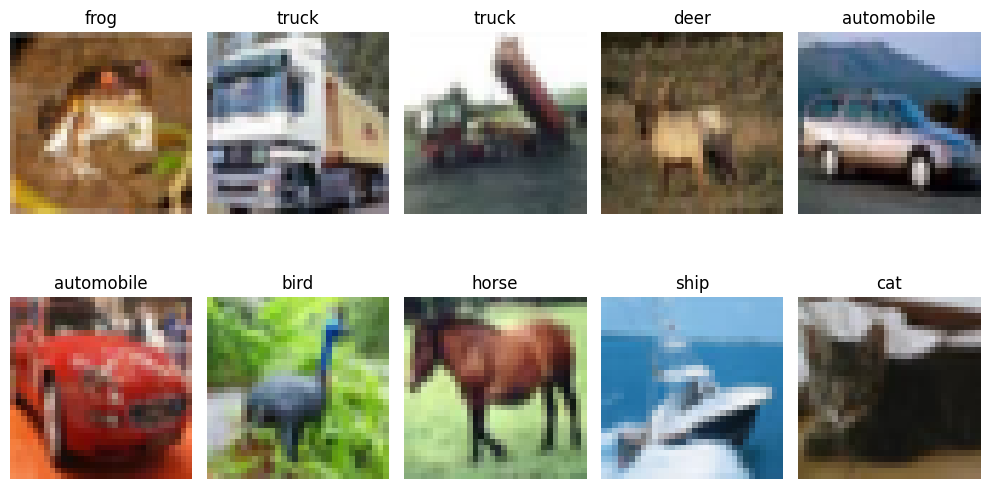

In [6]:
plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step - 3 Preprocessing

- images are of resolution of 32x32 and mobileNet expects 96x96. We will need to preprocess
- MobileNetV2 preprocessing maps pixels from [0,255] to [-1, +1]
- So we will Preprocess, resize and scale

In [7]:
IMG_SIZE = 96

x_train_resized = tf.image.resize(
    x_train,
    [IMG_SIZE, IMG_SIZE]
)

x_test_resized = tf.image.resize(
    x_test,
    [IMG_SIZE, IMG_SIZE]
)

print(x_train_resized.shape)
print(x_test_resized.shape)

(5000, 96, 96, 3)
(1000, 96, 96, 3)


In [8]:
# MobileNetV2 preprocessing
x_train_processed = keras.applications.mobilenet_v2.preprocess_input(
    x_train_resized
)

x_test_processed = keras.applications.mobilenet_v2.preprocess_input(
    x_test_resized
)

print("Min:", tf.reduce_min(x_train_processed).numpy())
print("Max:", tf.reduce_max(x_train_processed).numpy())

Min: -1.0
Max: 1.0


So far:

CIFAR 10 (32x32) --> Resized (96x96) --> MobileNextV2 preprocessing (scaled down to [-1, +1])

# Step 4 - Building Float32 Baseline Model

In [9]:
NUM_CLASSES = 10

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet",
    alpha=0.35
)

base_model.trainable = False

2019640/2019640 [==============================] - 0s 0us/step


## adding our own classification head

In [10]:
inputs = keras.Input(shape=(96, 96, 3))

x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

baseline_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="MobileNetV2_CIFAR10"
)

baseline_model.summary()

Model: "MobileNetV2_CIFAR10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 96, 96, 3)]       0         
                                                                 
 mobilenetv2_0.35_96 (Funct  (None, 3, 3, 1280)        410208    
 ional)                                                          
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 10)                12810     
                                                                 
Total params: 423018 (1.61 MB)
Trainable params: 12810 (50.04 KB)
Non-trainable params: 410208 (1.56 MB)
_________________________________________________________________


- MobileNetV2 backbone produces a faeture map, then GlobalAveragePooling2D compresses the spatial feature maps.
- Finally, Dense(10) produces ten calss probabilities

# Step 5 - Training the baseline model

In [11]:
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = baseline_model.fit(
    x_train_processed,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
71/71 [==============================] - 11s 31ms/step - loss: 1.2998 - accuracy: 0.5640 - val_loss: 0.8518 - val_accuracy: 0.6960
Epoch 2/5
71/71 [==============================] - 1s 13ms/step - loss: 0.6978 - accuracy: 0.7669 - val_loss: 0.7242 - val_accuracy: 0.7520
Epoch 3/5
71/71 [==============================] - 1s 13ms/step - loss: 0.5786 - accuracy: 0.8076 - val_loss: 0.6834 - val_accuracy: 0.7780
Epoch 4/5
71/71 [==============================] - 1s 13ms/step - loss: 0.5080 - accuracy: 0.8367 - val_loss: 0.6526 - val_accuracy: 0.7800
Epoch 5/5
71/71 [==============================] - 1s 15ms/step - loss: 0.4547 - accuracy: 0.8556 - val_loss: 0.6554 - val_accuracy: 0.7800


In [13]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    x_test_processed,
    y_test,
    verbose=0
)

print(f"Baseline Test Accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Test Accuracy: 78.10%


# Step 6 - Helpers for size, accuracy and latency

In [14]:
def get_file_size_kb(path):
    return os.path.getsize(path) / 1024

def evaluate_tflite(tflite_bytes, x, y):
    """Run a TFLite model on every sample and return accuracy (%)."""
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    in_scale, in_zp = inp["quantization"]
    out_scale, out_zp = out["quantization"]

    x = np.asarray(x)
    correct = 0

    for i in range(len(x)):
        sample = x[i:i + 1]

        # integer models need the float input mapped to int8 first
        if inp["dtype"] == np.int8:
            sample = np.round(sample / in_scale + in_zp).astype(np.int8)
        else:
            sample = sample.astype(np.float32)

        interpreter.set_tensor(inp["index"], sample)
        interpreter.invoke()
        pred = interpreter.get_tensor(out["index"])

        if out["dtype"] == np.int8:
            pred = (pred.astype(np.float32) - out_zp) * out_scale

        correct += int(np.argmax(pred) == y[i])

    return correct / len(x) * 100

def measure_latency_ms(tflite_bytes, x, runs=200):
    """Average single-image invoke() time in milliseconds."""
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    in_scale, in_zp = inp["quantization"]

    sample = np.asarray(x[:1])
    if inp["dtype"] == np.int8:
        sample = np.round(sample / in_scale + in_zp).astype(np.int8)
    else:
        sample = sample.astype(np.float32)

    # warm-up
    for _ in range(10):
        interpreter.set_tensor(inp["index"], sample)
        interpreter.invoke()

    start = perf_counter()
    for _ in range(runs):
        interpreter.set_tensor(inp["index"], sample)
        interpreter.invoke()
    end = perf_counter()

    return (end - start) / runs * 1000

- get_file_size_kb gives the size of a saved model, which is what matters for flash memory on a microcontroller
- evaluate_tflite runs the TFLite interpreter image by image. For INT8 models, the float input is first mapped to int8 using the input scale and zero point, and the output is mapped back to float before argmax
- measure_latency_ms times only interpreter.invoke() on one image, after a warm-up, so one-time setup cost is not counted
- Same helpers are used for every model, so the comparison is fair

# Step 7 - Float32 TFLite reference

In [15]:
converter = tf.lite.TFLiteConverter.from_keras_model(baseline_model)
tflite_float = converter.convert()

with open("baseline_float32.tflite", "wb") as f:
    f.write(tflite_float)

float_size_kb = get_file_size_kb("baseline_float32.tflite")
float_acc = evaluate_tflite(tflite_float, x_test_processed.numpy(), y_test)

print(f"Float32 TFLite size    : {float_size_kb:.1f} KB")
print(f"Float32 TFLite accuracy: {float_acc:.2f}%")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Float32 TFLite size    : 1600.0 KB
Float32 TFLite accuracy: 78.10%


- Keras baseline is converted to TFLite without quantization, so this is the float32 reference for size and latency
- Size is 1600 KB and accuracy is 78.10%, which is almost the same as the Keras baseline (78.20%). The 0.1 point gap is one image out of 1,000 flipping because of tiny numerical differences in the converter

# Step 8 - PTQ branch: Calibrate and convert to INT8

- Post-Training Quantization needs no retraining, only a small calibration set
- The representative dataset lets the converter observe the range of activations at each layer, which it uses to choose the INT8 scale and zero point
- We use 200 training images for calibration

In [16]:
def representative_dataset():
    for i in range(200):
        yield [x_train_processed[i:i + 1].numpy().astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(baseline_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_ptq = converter.convert()

with open("ptq_int8.tflite", "wb") as f:
    f.write(tflite_ptq)

ptq_size_kb = get_file_size_kb("ptq_int8.tflite")
print(f"PTQ INT8 size: {ptq_size_kb:.1f} KB")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


PTQ INT8 size: 613.0 KB


In [17]:
ptq_acc = evaluate_tflite(tflite_ptq, x_test_processed.numpy(), y_test)
ptq_latency = measure_latency_ms(tflite_ptq, x_test_processed.numpy())

print(f"PTQ INT8 accuracy: {ptq_acc:.2f}%")
print(f"PTQ INT8 latency : {ptq_latency:.3f} ms/image")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


PTQ INT8 accuracy: 47.00%
PTQ INT8 latency : 0.774 ms/image


- PTQ model is 613 KB versus 1600 KB for float32, which is a 2.6x reduction. This is less than the ideal 4x because the file also stores scales, zero points and int32 biases, and not every part of the model shrinks by 4x
- Accuracy collapsed from 78.10% to 47.00%, a drop of 31.1 points. The model was never trained with quantization noise and only 200 calibration images were used to fix the activation ranges, so the INT8 rounding error was large for MobileNetV2
- Latency went up from 0.418 ms to 0.774 ms. The INT8 model is slower here because this is a general CPU, not an embedded chip with optimised INT8 kernels, so this should not be read as the speed on a microcontroller

# Step 9 - QAT branch: Fine-tune with fake quantization

- QAT inserts fake-quantization nodes into the model, so training sees the rounding error of INT8 and the weights can adapt to it
- tfmot cannot wrap a model nested inside another model, so we rebuild a flat model from the same MobileNetV2 layers and the same trained Dense head

In [18]:
# flat model: backbone layers + trained head (no nested Model)
x = base_model.output
x = baseline_model.layers[-2](x)        # GlobalAveragePooling2D
outputs = baseline_model.layers[-1](x)  # trained Dense head

flat_model = keras.Model(inputs=base_model.input, outputs=outputs, name="flat_MobileNetV2_CIFAR10")

qat_model = tfmot.quantization.keras.quantize_model(flat_model)

qat_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

qat_model.summary()

Model: "flat_MobileNetV2_CIFAR10"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 96, 96, 3)]          0         []                            
                                                                                                  
 quantize_layer (QuantizeLa  (None, 96, 96, 3)            3         ['input_1[0][0]']             
 yer)                                                                                             
                                                                                                  
 quant_Conv1 (QuantizeWrapp  (None, 48, 48, 16)           465       ['quantize_layer[0][0]']      
 erV2)                                                                                            
                                                                           

- QAT model has 432,204 params versus 423,018 in the baseline, the extra ones are the min/max values the quantizers learn for every layer
- Trainable params are 394,858 because the backbone is now unfrozen, so the whole network can adapt to quantization noise

In [19]:
# accuracy of the fake-quantized model before any fine-tuning
_, qat_before_acc = qat_model.evaluate(x_test_processed, y_test, verbose=0)
print(f"QAT model before fine-tuning: {qat_before_acc * 100:.2f}%")

QAT model before fine-tuning: 10.30%


In [20]:
qat_history = qat_model.fit(
    x_train_processed,
    y_train,
    validation_split=0.1,
    epochs=3,
    batch_size=64,
    verbose=1
)

Epoch 1/3
71/71 [==============================] - 29s 137ms/step - loss: 1.3773 - accuracy: 0.5067 - val_loss: 1.0028 - val_accuracy: 0.6380
Epoch 2/3
71/71 [==============================] - 9s 131ms/step - loss: 0.7999 - accuracy: 0.7176 - val_loss: 0.8693 - val_accuracy: 0.7040
Epoch 3/3
71/71 [==============================] - 9s 131ms/step - loss: 0.6014 - accuracy: 0.7949 - val_loss: 0.6148 - val_accuracy: 0.7720


In [21]:
_, qat_keras_acc = qat_model.evaluate(x_test_processed, y_test, verbose=0)
print(f"QAT model after fine-tuning (Keras): {qat_keras_acc * 100:.2f}%")

QAT model after fine-tuning (Keras): 76.80%


- Accuracy before fine-tuning is 10.30%, which is random guessing for 10 classes. The fake-quantization ranges have not been calibrated yet, so the model is unusable until it is trained
- After 3 epochs, validation accuracy rose from 63.8% to 77.2% and test accuracy reached 76.80%, only 1.4 points below the Keras baseline
- So a short fine-tune is enough for the weights and quantizer ranges to adapt to INT8 rounding
- This is still fake quantization inside Keras, so the real INT8 TFLite numbers come next

## Convert QAT model to INT8 TFLite

In [22]:
converter = tf.lite.TFLiteConverter.from_keras_model(qat_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_qat = converter.convert()

with open("qat_int8.tflite", "wb") as f:
    f.write(tflite_qat)

qat_size_kb = get_file_size_kb("qat_int8.tflite")
qat_acc = evaluate_tflite(tflite_qat, x_test_processed.numpy(), y_test)
qat_latency = measure_latency_ms(tflite_qat, x_test_processed.numpy())

print(f"QAT INT8 size    : {qat_size_kb:.1f} KB")
print(f"QAT INT8 accuracy: {qat_acc:.2f}%")
print(f"QAT INT8 latency : {qat_latency:.3f} ms/image")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


QAT INT8 size    : 618.4 KB
QAT INT8 accuracy: 76.50%
QAT INT8 latency : 0.706 ms/image


- QAT INT8 model is 618 KB, about the same as PTQ (613 KB), because both store 8 bit weights. The small difference comes from the extra quantization parameters
- Accuracy is 76.50%, almost the same as the 76.80% Keras QAT result, so the conversion kept what fine-tuning learned
- Latency is 0.706 ms, similar to PTQ (0.774 ms), so the speed difference between PTQ and QAT is small and comes from the CPU, not the method

# Step 10 - Compare: size, accuracy, latency

In [23]:
float_latency = measure_latency_ms(tflite_float, x_test_processed.numpy())

results = pd.DataFrame({
    "Model": ["Float32 baseline", "PTQ INT8", "QAT INT8"],
    "Size (KB)": [float_size_kb, ptq_size_kb, qat_size_kb],
    "Accuracy (%)": [float_acc, ptq_acc, qat_acc],
    "Latency (ms/img)": [float_latency, ptq_latency, qat_latency],
})

results["Size reduction (x)"] = results["Size (KB)"].iloc[0] / results["Size (KB)"]
results["Accuracy drop (pts)"] = results["Accuracy (%)"].iloc[0] - results["Accuracy (%)"]

results.round(3)

,Model,Size (KB),Accuracy (%),Latency (ms/img),Size reduction (x),Accuracy drop (pts)
0,Float32 baseline,1600.027,78.1,0.418,1.000,0.0
1,PTQ INT8,612.969,47.0,0.774,2.610,31.1
2,QAT INT8,618.352,76.5,0.706,2.588,1.6


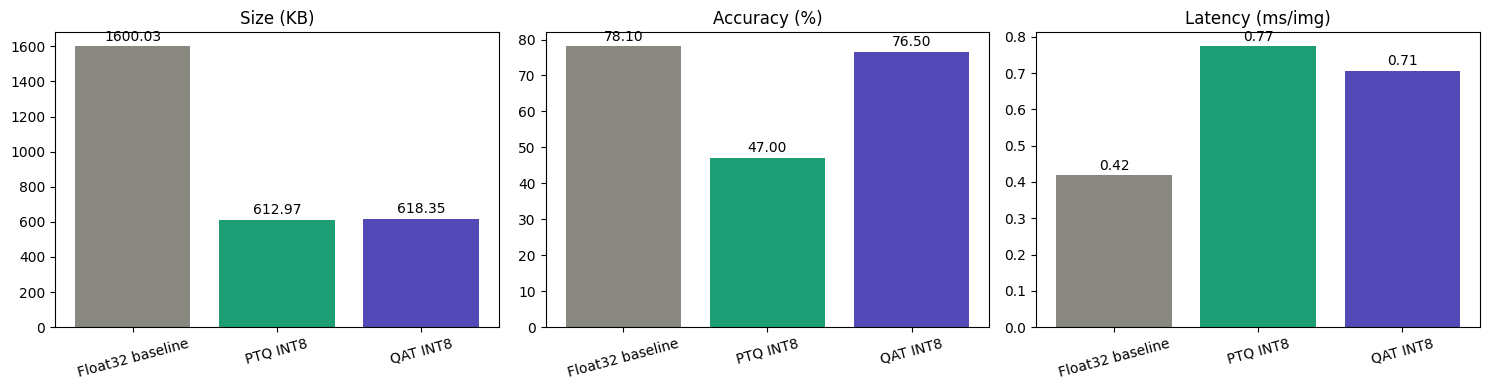

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#888780", "#1D9E75", "#534AB7"]

for ax, col in zip(axes, ["Size (KB)", "Accuracy (%)", "Latency (ms/img)"]):
    bars = ax.bar(results["Model"], results[col], color=colors)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=15)
    ax.bar_label(bars, fmt="%.2f", padding=2)

plt.tight_layout()
plt.show()

- Size: both INT8 models are around 2.6x smaller than float32 (1600 KB to about 615 KB), and PTQ and QAT are almost identical in size
- Accuracy: float32 is 78.10%, QAT is 76.50% (drop of 1.6 points) and PTQ is 47.00% (drop of 31.1 points). QAT keeps nearly all the accuracy while PTQ loses almost a third
- Latency: float32 is the fastest at 0.418 ms and both INT8 models are slower (0.706 and 0.774 ms), because this CPU has no special INT8 acceleration
- QAT gives the best trade-off here: same size saving as PTQ with only a small accuracy loss

# Step 11 - Report

### Q1. How much smaller did INT8 quantization make the model?
- Float32 TFLite is 1600 KB, PTQ is 613 KB and QAT is 618 KB, so both are about 2.6x smaller
- It is below the theoretical 4x because of the quantization parameters and int32 biases stored along with the weights

### Q2. How much accuracy did PTQ lose compared to float32?
- PTQ dropped from 78.10% to 47.00%, a loss of 31.1 points
- Calibrating on only 200 images without any retraining was not enough for this small MobileNetV2 (alpha 0.35) to survive INT8 rounding

### Q3. Did QAT recover accuracy compared to PTQ, and why?
- Yes. QAT reached 76.50%, only 1.6 points below float32 and 29.5 points above PTQ
- Fine-tuning with fake quantization let the weights and activation ranges adapt to INT8 rounding error, while PTQ only measured ranges and could not change the weights
- Before fine-tuning the QAT model was at 10.30%, so the training step is what made it work

### Q4. How did latency change, and is this result reliable for a microcontroller?
- Float32 was 0.418 ms, PTQ 0.774 ms and QAT 0.706 ms, so INT8 was slower on this machine
- It is not reliable for a microcontroller. This was measured on a general CPU without optimised INT8 kernels, and the speedup of INT8 depends on the target hardware. The size reduction is the benefit that carries over

### Q5. When would you choose PTQ over QAT?
- PTQ when there is no time or labelled data for retraining and the model tolerates quantization well, since it only needs a small calibration set
- QAT when PTQ loses too much accuracy, as it did here (47.00%), and training is affordable

## Conclusion
- Quantizing MobileNetV2 to INT8 cut the model size from 1600 KB to about 615 KB (2.6x)
- PTQ was quick but cost 31.1 accuracy points, QAT cost only 1.6 points with 3 epochs of fine-tuning
- Latency did not improve on this CPU, so the benefit measured here is memory, which matters on a microcontroller
- For this model QAT is the right choice